# Bab 12 — *Cross-Validation* dan Teknik Evaluasi Model

**Buku:** *scikit-learn Cookbook, Third Edition* — John Sukup (Packt, 2025), Bab 12
**Sumber kode:** [PacktPublishing/Scikit-Learn-Cookbook-Third-Edition](https://github.com/PacktPublishing/Scikit-Learn-Cookbook-Third-Edition) (`Chapter_12`)
**Direproduksi dan dijelaskan oleh:** Hadi Nugroho — NIM 101032330235 — S1 Teknik Komputer, Telkom University

**Resep yang dibahas**

| # | Resep | Alat utama |
|---|--------|-----------|
| 12.1 | Pengantar *Cross-Validation*: k-fold dan *stratified* k-fold | `KFold`, `StratifiedKFold` |
| 12.2 | Metode *Cross-Validation* Lanjutan | `LeaveOneOut`, *nested CV* (`GridSearchCV` di dalam `cross_val_score`) |
| 12.3 | Mengimplementasikan *Cross-Validation* di scikit-learn | `cross_val_score`, `cross_validate`, `GridSearchCV` |
| 12.4 | Teknik Pemilihan Model | `GridSearchCV`, `RandomizedSearchCV`, `loguniform` |
| 12.5 | Mengevaluasi Kemampuan Generalisasi Model | `learning_curve`, `validation_curve` |
| 12.6 | Latihan Praktis *Cross-Validation* dan Evaluasi | `cross_validate` multi-metrik, *grid search* SVC, kurva belajar dan validasi |

> Nomor resep ditambahkan di sini untuk memudahkan navigasi; buku aslinya tidak menomori resep. Resep 12.6 memakai solusi resmi dari notebook *Exercise Solutions* di repositori.

## Gambaran Umum Bab

Di bab-bab sebelumnya, model hampir selalu dinilai dengan **satu** pembagian latih/uji. Angka yang dihasilkan bergantung pada keberuntungan pembagian itu: pada data kecil, beberapa sampel "sulit" yang kebetulan masuk data uji bisa menggeser akurasi beberapa poin (misalnya selisih dua bunga pada 45 bunga uji Iris di Bab 8). ***Cross-validation*** (CV) mengatasi hal ini dengan melatih dan menguji model berkali-kali pada bagian data yang berbeda lalu merata-ratakan hasilnya, sehingga diperoleh estimasi kinerja yang lebih stabil **beserta** sebarannya.

Bab ini membahas varian CV (k-fold, *stratified*, *leave-one-out*, *nested*), API scikit-learn untuk menjalankannya, cara memakai CV untuk memilih hiperparameter tanpa "mengintip" data uji (*grid search* dan *randomized search*), serta dua diagnosis grafis: ***learning curve*** (apakah menambah data akan membantu?) dan ***validation curve*** (apakah model *underfit* atau *overfit* pada nilai hiperparameter tertentu?). Topik ini menjawab beberapa masalah yang muncul di bab sebelumnya: hasil *grid search* yang seri, skor CV yang terlalu optimis, dan data uji yang kecil.

## Persiapan

In [1]:
# Pustaka inti yang dipakai di sepanjang bab ini
import sys
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import sklearn

# Satu seed global agar setiap eksekusi notebook menghasilkan angka yang sama.
# (Sel-sel buku tetap memakai nilai random_state masing-masing.)
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

# Catat lingkungan persis yang menghasilkan output di bawah
print(f"Python       : {sys.version.split()[0]}")
print(f"numpy        : {np.__version__}")
print(f"pandas       : {pd.__version__}")
print(f"scikit-learn : {sklearn.__version__}")
print(f"matplotlib   : {matplotlib.__version__}")

Python       : 3.13.17
numpy        : 2.1.3
pandas       : 2.2.3
scikit-learn : 1.5.2
matplotlib   : 3.9.4


## Resep 12.1 — Pengantar *Cross-Validation*: k-fold dan *Stratified* k-fold

**Tujuan.** Mengevaluasi regresi logistik pada 500 sampel sintetis dengan *k-fold* biasa dan *stratified k-fold* (k = 5), lalu membandingkan rata-rata akurasinya.

### Teori

**Intuisi.** Bagi data menjadi $k$ bagian (*fold*) yang kira-kira sama besar. Untuk setiap fold, latih model pada $k-1$ fold lain dan uji pada fold itu. Setiap sampel dipakai tepat sekali sebagai data uji, sehingga semua data ikut menilai model. ***Stratified* k-fold** menambahkan satu syarat: proporsi kelas di setiap fold sama dengan proporsi di seluruh data. Ini penting untuk kelas yang tidak seimbang, karena fold acak bisa saja hampir tidak memuat kelas minoritas.

**Matematika.** Estimasi CV dari metrik $M$:
$$\widehat{M}_{\text{CV}}=\frac1k\sum_{j=1}^{k}M\big(f^{(-j)},\,D_j\big),$$
dengan $f^{(-j)}$ model yang dilatih tanpa fold $D_j$. Variansi estimasi ini berasal dari dua sumber: variasi antar-fold (terlihat dari simpangan baku skor fold) dan korelasi antar-model (setiap dua model berbagi $(k-2)/(k-1)$ data latih). Nilai $k=5$ atau $10$ adalah kompromi umum antara bias (fold latih lebih kecil dari data penuh) dan variansi/biaya.

**Cara scikit-learn mengimplementasikannya.**

* `KFold(n_splits=5, shuffle=False, random_state=None)`: tanpa `shuffle`, fold diambil berurutan dari atas data. `shuffle=True` + `random_state` membuat fold acak tetapi dapat diulang.
* `StratifiedKFold(n_splits=5, shuffle=False, random_state=None)`: `split(X, y)` membutuhkan `y` untuk menjaga proporsi kelas.
* Keduanya hanya menghasilkan **indeks**; loop latih/uji ditulis manual di resep ini (resep 12.3 memakai fungsi bantu).

**Asumsi, kelebihan, keterbatasan.**

* CV mengasumsikan sampel independen dan berdistribusi identik. Data deret waktu butuh `TimeSeriesSplit`, data berkelompok (pasien, rumah) butuh `GroupKFold`.
* Biaya $k$ kali pelatihan.
* Pada data seimbang (seperti di resep ini), stratifikasi hampir tidak berpengaruh; manfaatnya terlihat pada data tidak seimbang dan data kecil.

### Kode

In [2]:
# Muat pustaka
import numpy as np
from sklearn.datasets import make_classification
from sklearn.model_selection import KFold, StratifiedKFold
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

# Muat dataset
X, y = make_classification(n_samples=500, n_features=10, n_informative=8,
                           n_redundant=2, n_classes=2, random_state=2024)

In [3]:
# Inisialisasi cross-validator k-fold
kf = KFold(n_splits=5, shuffle=True, random_state=2024)

# Iterasi setiap fold dan evaluasi
accuracies = []
for train_index, test_index in kf.split(X):
    X_train, X_test = X[train_index], X[test_index]
    y_train, y_test = y[train_index], y[test_index]
    model = LogisticRegression()
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    accuracies.append(accuracy_score(y_test, y_pred))
print(f"Average accuracy (KFold): {np.mean(accuracies):.3f}")

# Gunakan stratified k-fold agar pembagian kelas seimbang
strat_kf = StratifiedKFold(n_splits=5, shuffle=True, random_state=2024)
strat_accuracies = []
for train_index, test_index in strat_kf.split(X, y):
    X_train, X_test = X[train_index], X[test_index]
    y_train, y_test = y[train_index], y[test_index]
    model = LogisticRegression()
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    strat_accuracies.append(accuracy_score(y_test, y_pred))
print(f"Average accuracy (StratifiedKFold): {np.mean(strat_accuracies):.3f}")

Average accuracy (KFold): 0.756
Average accuracy (StratifiedKFold): 0.766


In [4]:
# Akurasi per fold dan proporsi kelas 1 di setiap fold uji (tambahan)
print(f"proporsi kelas 1 di seluruh data = {y.mean():.3f}")
for name, cv, accs in [("KFold", kf, accuracies), ("StratifiedKFold", strat_kf, strat_accuracies)]:
    props = [y[test].mean() for _, test in cv.split(X, y)]
    print(f"{name:>15}: akurasi fold = {np.round(accs, 3)} (sd {np.std(accs):.3f}) | proporsi kelas 1 per fold = {np.round(props, 3)}")

# Pembanding: data tidak seimbang (10 % positif), 20 pengulangan acak
Xi, yi = make_classification(n_samples=200, n_features=10, weights=[0.9, 0.1], random_state=2024)
spread = {}
for name, cls in [("KFold", KFold), ("StratifiedKFold", StratifiedKFold)]:
    spread[name] = [np.std([yi[t].mean() for _, t in cls(5, shuffle=True, random_state=r).split(Xi, yi)]) for r in range(20)]
print("data 10 % positif -> rata-rata sd proporsi positif antar fold:",
      {k: round(float(np.mean(v)), 4) for k, v in spread.items()})

proporsi kelas 1 di seluruh data = 0.500
          KFold: akurasi fold = [0.72 0.72 0.88 0.71 0.75] (sd 0.063) | proporsi kelas 1 per fold = [0.52 0.47 0.54 0.51 0.46]
StratifiedKFold: akurasi fold = [0.79 0.76 0.76 0.76 0.76] (sd 0.012) | proporsi kelas 1 per fold = [0.5 0.5 0.5 0.5 0.5]


data 10 % positif -> rata-rata sd proporsi positif antar fold: {'KFold': 0.0445, 'StratifiedKFold': 0.01}


**Interpretasi output.**

* Rata-rata akurasi **0,756** (k-fold) vs **0,766** (*stratified*). Selisih 0,01 itu lebih kecil daripada variasi antar-fold k-fold biasa (sd 0,063, dengan akurasi fold 0,71 sampai 0,88), jadi tidak bisa disimpulkan bahwa stratifikasi "meningkatkan akurasi". Yang berubah adalah **cara data dibagi**, bukan modelnya.
* Data ini seimbang (50 % kelas 1). K-fold biasa menghasilkan proporsi kelas 1 per fold antara 0,46 dan 0,54, sedangkan *stratified* tepat 0,50 di setiap fold. Akurasi per fold *stratified* juga jauh lebih seragam (sd 0,012).
* Teks buku menyebut stratifikasi penting untuk kelas tidak seimbang, tetapi data resepnya seimbang. Sel tambahan menguji kasus yang dimaksud: pada data 10 % positif (200 sampel, 20 pengulangan), simpangan baku proporsi positif antar-fold turun dari **0,045** (k-fold) menjadi **0,010** (*stratified*). Dengan hanya ±4 sampel positif per fold, variasi sebesar itu bisa membuat satu fold nyaris tanpa kelas positif.

### Poin Penting
* k-fold memakai setiap sampel tepat sekali sebagai data uji; hasilnya rata-rata **dan** sebaran skor.
* *Stratified* k-fold menjaga proporsi kelas tiap fold (tepat 0,50 di sini); pada data 10 % positif, sebaran proporsi antar-fold turun dari 0,045 ke 0,010.
* Selisih rata-rata 0,756 vs 0,766 lebih kecil daripada sd antar-fold (0,063), jadi bukan perbedaan yang bermakna.

## Resep 12.2 — Metode *Cross-Validation* Lanjutan

**Tujuan.** Menerapkan *leave-one-out* CV (LOOCV) pada regresi Ridge untuk data Diabetes, lalu *nested* CV yang men-*tuning* `alpha` di loop dalam dan menilai kinerja di loop luar.

### Teori

**Intuisi.**

* **LOOCV** adalah k-fold dengan $k=n$: setiap kali satu sampel diuji dan sisanya untuk latih. Hampir tidak ada data yang "terbuang", sehingga biasnya kecil, tetapi butuh $n$ kali pelatihan dan skor per fold (satu sampel) sangat berisik.
* ***Nested* CV** memisahkan dua pekerjaan yang sering tercampur: **memilih** hiperparameter (loop dalam) dan **menilai** model yang terpilih (loop luar). Jika skor terbaik *grid search* langsung dilaporkan sebagai kinerja, angkanya optimis, karena hiperparameter dipilih justru karena skor itu tinggi. Pada *nested* CV, setiap fold luar menjalankan *grid search* sendiri tanpa pernah melihat fold uji luar.

**Matematika.** LOOCV untuk MSE: $\widehat{\text{MSE}}_{\text{LOO}}=\frac1n\sum_{i=1}^n\big(y_i-\hat f^{(-i)}(\mathbf{x}_i)\big)^2$. *Nested* CV dengan $K_{\text{out}}$ fold luar:
$$\widehat{M}_{\text{nested}}=\frac{1}{K_{\text{out}}}\sum_{j=1}^{K_{\text{out}}}M\Big(f^{(-j)}_{\hat\lambda_j},D_j\Big),\qquad \hat\lambda_j=\arg\max_\lambda \widehat{M}_{\text{CV}}^{\text{(dalam)}}(\lambda;\,D\setminus D_j).$$
Ridge meminimalkan $\lVert\mathbf{y}-X\boldsymbol\beta\rVert^2+\alpha\lVert\boldsymbol\beta\rVert^2$ (Bab 5).

**Cara scikit-learn mengimplementasikannya.**

* `LeaveOneOut()` sebagai argumen `cv`; untuk regresi, metrik per fold harus dapat dihitung dari satu sampel (MSE bisa, $R^2$ tidak).
* `cross_val_score(GridSearchCV(est, grid, cv=5), X, y, cv=5)` adalah *nested* CV: objek `GridSearchCV` diperlakukan sebagai satu estimator yang di-*fit* ulang di setiap fold luar.
* Skor default regresi adalah $R^2$; `scoring="neg_mean_squared_error"` mengembalikan **negatif** MSE (konvensi "makin besar makin baik").

**Asumsi, kelebihan, keterbatasan.**

* LOOCV mahal dan variansinya tinggi; 5- atau 10-fold biasanya lebih praktis.
* *Nested* CV memberi estimasi yang jujur untuk **prosedur** "tuning + fit", bukan untuk satu model tertentu; setiap fold luar bisa memilih hiperparameter berbeda.
* Di sel buku, LOOCV memakai MSE sedangkan *nested* CV memakai $R^2$ default, sehingga kedua angka tidak bisa dibandingkan langsung (sel tambahan menghitung keduanya dalam satuan yang sama).

### Kode

In [5]:
# Muat pustaka
import numpy as np
from sklearn.datasets import load_diabetes
from sklearn.model_selection import LeaveOneOut, GridSearchCV, cross_val_score
from sklearn.linear_model import Ridge

# Muat dataset
data = load_diabetes()
X = data.data
y = data.target

In [6]:
# Terapkan Leave-One-Out cross-validation dengan skor MSE
loo = LeaveOneOut()
model = Ridge(alpha=1.0)
scores = cross_val_score(model, X, y, cv=loo, scoring="neg_mean_squared_error")
print(f"LOOCV mean MSE: {-np.mean(scores):.3f}")

# Tentukan grid untuk tuning hiperparameter
param_grid = {"alpha": [0.01, 0.1, 1, 10, 100]}

# Terapkan nested cross-validation dengan GridSearchCV (skor default sudah cukup untuk CV luar)
nested_scores = cross_val_score(
    GridSearchCV(Ridge(), param_grid, cv=5), X, y, cv=5
)
print(f"Nested CV mean score: {np.mean(nested_scores):.3f}")

LOOCV mean MSE: 3327.655


Nested CV mean score: 0.480


In [7]:
# Konteks angka di atas: skala target, pembanding 5-fold, alpha yang dipilih tiap fold luar (tambahan)
from sklearn.model_selection import cross_validate, KFold
print(f"Diabetes: n = {X.shape[0]}, fitur = {X.shape[1]}, target: mean {y.mean():.1f}, var {y.var():.1f}")
print(f"LOOCV: {len(scores)} fit, RMSE = {np.sqrt(-np.mean(scores)):.2f}")
mse5 = -cross_val_score(Ridge(alpha=1.0), X, y, cv=5, scoring="neg_mean_squared_error")
print(f"5-fold (Ridge alpha=1): MSE = {mse5.mean():.3f}")
print("skor R² nested per fold luar:", np.round(nested_scores, 3))
nested = cross_validate(GridSearchCV(Ridge(), param_grid, cv=5), X, y, cv=5, return_estimator=True,
                        scoring={"r2": "r2", "mse": "neg_mean_squared_error"})
print("alpha terpilih per fold luar:", [est.best_params_["alpha"] for est in nested["estimator"]])
print(f"nested CV dalam MSE = {-nested['test_mse'].mean():.3f}")
gs_full = GridSearchCV(Ridge(), param_grid, cv=5).fit(X, y)
print(f"skor terbaik GridSearchCV tanpa loop luar (R²) = {gs_full.best_score_:.3f} dengan alpha = {gs_full.best_params_['alpha']}")

Diabetes: n = 442, fitur = 10, target: mean 152.1, var 5929.9
LOOCV: 442 fit, RMSE = 57.69
5-fold (Ridge alpha=1): MSE = 3420.324
skor R² nested per fold luar: [0.411 0.52  0.492 0.44  0.537]


alpha terpilih per fold luar: [0.1, 0.01, 0.1, 0.1, 0.1]
nested CV dalam MSE = 3004.708
skor terbaik GridSearchCV tanpa loop luar (R²) = 0.481 dengan alpha = 0.01


**Interpretasi output.**

* **LOOCV** melatih Ridge (`alpha=1`) sebanyak **442 kali**. MSE rata-ratanya **3.327,7** (RMSE ≈ 57,7 pada target yang bervariansi 5.929,9), kira-kira sama dengan 5-fold biasa (3.420,3). Pada data berukuran ratusan, LOOCV tidak memberi banyak informasi tambahan dibanding 5-fold tetapi butuh hampir 90 kali lebih banyak pelatihan.
* ***Nested* CV** melaporkan **0,480**, dan angka ini adalah **$R^2$**, bukan MSE, karena `cross_val_score` tanpa `scoring` memakai skor default estimator. Kedua angka di sel buku berbeda satuan. Dalam satuan yang sama, *nested* CV memberi MSE **3.004,7**, lebih kecil dari LOOCV karena *grid search* di dalamnya memilih `alpha` yang lebih kecil daripada 1.
* Setiap fold luar memilih `alpha` sendiri: 0,1 pada empat fold dan 0,01 pada satu fold. Skor $R^2$ fold luar berkisar 0,41–0,54.
* Skor terbaik *grid search* tanpa loop luar adalah 0,481, hampir sama dengan hasil *nested* (0,480). Optimisme seleksi di sini sangat kecil karena grid hanya 5 nilai dan modelnya sederhana; pada grid besar dan model fleksibel, selisihnya bisa jauh lebih besar.

### Poin Penting
* LOOCV = k-fold dengan $k=n$ (442 fit); MSE 3.327,7, hampir sama dengan 5-fold (3.420,3).
* *Nested* CV menilai **prosedur** tuning + fit; `alpha` terpilih berbeda antar-fold (0,1 dan 0,01).
* Sel buku membandingkan MSE (LOOCV) dengan $R^2$ (*nested*); selalu periksa metrik yang dipakai.

## Resep 12.3 — Mengimplementasikan *Cross-Validation* di scikit-learn

**Tujuan.** Memakai tiga fungsi tingkat tinggi scikit-learn (`cross_val_score`, `cross_validate`, `GridSearchCV`) pada data biner tidak seimbang (70 % / 30 %).

### Teori

**Intuisi.** Loop manual di Resep 12.1 mudah salah (misalnya lupa membuat model baru di setiap fold). scikit-learn menyediakan fungsi yang melakukan seluruh proses: membagi data, meng-*clone* estimator, melatih, menilai, dan mengumpulkan skor.

**Matematika.** Untuk klasifikasi, argumen `cv=5` (bilangan bulat) berarti **`StratifiedKFold(5)` tanpa *shuffle***. Dengan kelas positif = 1: akurasi, $P=\frac{TP}{TP+FP}$, $R=\frac{TP}{TP+FN}$, $F1=\frac{2PR}{P+R}$, masing-masing dihitung per fold lalu dirata-ratakan. *Grid search* memilih $\hat C=\arg\max_C\widehat{M}_{\text{CV}}(C)$ lalu melatih ulang model dengan $\hat C$ pada **seluruh** data (`refit=True`).

**Cara scikit-learn mengimplementasikannya.**

* `cross_val_score(est, X, y, cv=5, scoring='accuracy')` → array skor satu metrik.
* `cross_validate(est, X, y, cv=5, scoring=[...], return_train_score=False)` → *dictionary* berisi `test_<metrik>`, `fit_time`, `score_time` untuk banyak metrik sekaligus.
* `GridSearchCV(est, param_grid, cv=5, scoring=...)` → setelah `fit`: `best_params_`, `best_score_` (rata-rata CV terbaik), `best_estimator_`, dan `cv_results_` lengkap.
* `LogisticRegression()` default: penalti L2 dengan `C=1.0`; $C$ adalah **kebalikan** kekuatan regularisasi.

**Asumsi, kelebihan, keterbatasan.**

* Fungsi-fungsi ini meng-*clone* estimator, jadi tidak ada kebocoran antar-fold, **asalkan** pra-pemrosesan ada di dalam `Pipeline` (Bab 2).
* `best_score_` dari *grid search* bersifat optimis (lihat Resep 12.2); di resep ini *grid search* dijalankan pada seluruh data tanpa data uji terpisah.

### Kode

In [8]:
# Muat pustaka
import numpy as np
from sklearn.datasets import make_classification
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_score, cross_validate, GridSearchCV

# Muat dan siapkan dataset
X, y = make_classification(n_samples=500, n_features=10, weights=[0.7, 0.3], random_state=2024)

In [9]:
# Gunakan cross_val_score() untuk menghitung rata-rata akurasi
model = LogisticRegression()
scores = cross_val_score(model, X, y, cv=5, scoring='accuracy')
print(f"Mean accuracy: {np.mean(scores):.3f}")

# Gunakan cross_validate() untuk menghitung beberapa metrik
results = cross_validate(model, X, y, cv=5,
                         scoring=['accuracy', 'precision', 'recall', 'f1'])
print(f"Mean precision: {np.mean(results['test_precision']):.3f}")
print(f"Mean recall: {np.mean(results['test_recall']):.3f}")
print(f"Mean F1: {np.mean(results['test_f1']):.3f}")

# Gunakan GridSearchCV() untuk tuning hiperparameter dengan cross-validation
param_grid = {"C": [0.01, 0.1, 1, 10]}
grid = GridSearchCV(LogisticRegression(), param_grid, cv=5, scoring='accuracy')
grid.fit(X, y)
print(f"Best hyperparameter (C): {grid.best_params_['C']}")
print(f"Best accuracy: {grid.best_score_:.3f}")

Mean accuracy: 0.910
Mean precision: 0.875
Mean recall: 0.820
Mean F1: 0.845


Best hyperparameter (C): 0.1
Best accuracy: 0.918


In [10]:
# Proporsi kelas, skor per fold, dan papan peringkat grid (tambahan)
print(f"proporsi kelas 1 = {y.mean():.3f}; baseline 'selalu kelas 0' = {1 - y.mean():.3f}")
print("akurasi per fold:", np.round(scores, 3), f"| sd = {scores.std():.3f}")
print("kunci hasil cross_validate:", sorted(results))
lb = pd.DataFrame(grid.cv_results_)[["param_C", "mean_test_score", "std_test_score", "rank_test_score"]]
display(lb.round(4))

proporsi kelas 1 = 0.300; baseline 'selalu kelas 0' = 0.700
akurasi per fold: [0.87 0.92 0.87 0.95 0.94] | sd = 0.034
kunci hasil cross_validate: ['fit_time', 'score_time', 'test_accuracy', 'test_f1', 'test_precision', 'test_recall']


,param_C,mean_test_score,std_test_score,rank_test_score
0,0.01,0.894,0.0206,4
1,0.10,0.918,0.0360,1
2,1.00,0.910,0.0341,2
3,10.00,0.908,0.0366,3


**Interpretasi output.**

* Data ini tidak seimbang (30 % kelas 1), sehingga *baseline* "selalu kelas 0" sudah mendapat 0,700. Regresi logistik default mencapai akurasi **0,910**, jauh di atas *baseline*.
* `cross_validate` mengembalikan semua metrik sekaligus: *precision* **0,875**, *recall* **0,820**, F1 **0,845** untuk kelas 1. *Recall* lebih rendah daripada *precision*: model lebih sering **melewatkan** sampel kelas minoritas daripada salah menandai kelas mayoritas, pola yang umum pada data tidak seimbang.
* `GridSearchCV` memilih **C = 0,1** dengan akurasi CV **0,918**. Papan peringkat memperlihatkan selisih antar-kandidat sangat kecil (0,894–0,918) dibandingkan simpangan baku per kandidat (0,02–0,04), jadi pilihan C = 0,1 tidak jauh lebih baik daripada default C = 1 (0,910).
* Karena *grid search* dijalankan pada seluruh data tanpa data uji terpisah, 0,918 adalah estimasi yang sedikit optimis; Resep 12.4 memperbaikinya dengan data uji yang disisihkan.

### Poin Penting
* `cross_val_score` (satu metrik), `cross_validate` (banyak metrik + waktu), dan `GridSearchCV` (tuning + refit) menggantikan loop manual.
* Pada data 70/30: akurasi 0,910, *precision* 0,875, *recall* 0,820; *recall* kelas minoritas paling lemah.
* C terbaik (0,1; 0,918) hanya sedikit di atas default (0,910), di dalam sebaran antar-fold.

## Resep 12.4 — Teknik Pemilihan Model

**Tujuan.** Memilih kekuatan regularisasi `C` regresi logistik dengan *grid search* (6 nilai) dan *randomized search* (10 sampel dari distribusi log-uniform), lalu menilai model terpilih pada data uji yang disisihkan.

### Teori

**Intuisi.** *Grid search* mencoba **semua** kombinasi nilai yang ditentukan; jumlah kombinasi tumbuh eksponensial terhadap jumlah hiperparameter. *Randomized search* mengambil sejumlah kombinasi **acak** dari distribusi yang ditentukan. Untuk anggaran evaluasi yang sama, *randomized search* menjelajahi lebih banyak nilai unik per hiperparameter, yang menguntungkan jika hanya sebagian hiperparameter yang benar-benar penting (Bergstra & Bengio, 2012).

**Matematika.** Distribusi **log-uniform** pada $[a,b]$: $\log C\sim\text{Uniform}(\log a,\log b)$, sehingga setiap dekade (0,001–0,01, 0,01–0,1, …) mendapat peluang yang sama. Ini cocok untuk parameter skala seperti $C$, yang pengaruhnya bersifat multiplikatif. Prosedurnya: (1) bagi data menjadi latih (70 %) dan uji (30 %); (2) pilih $\hat C$ dengan CV **hanya pada data latih**; (3) laporkan kinerja $f_{\hat C}$ pada data uji, yang tidak pernah dipakai saat memilih.

**Cara scikit-learn mengimplementasikannya.**

* `GridSearchCV(est, {"C": [...]}, cv=5, scoring='accuracy')`.
* `RandomizedSearchCV(est, param_distributions={"C": loguniform(1e-3, 1e2)}, n_iter=10, cv=5, random_state=...)`; distribusi berasal dari `scipy.stats` dan cukup punya metode `rvs`.
* Keduanya memakai `refit=True` sehingga `best_estimator_` sudah dilatih ulang pada seluruh data latih.

**Asumsi, kelebihan, keterbatasan.**

* *Randomized search* tidak menjamin menemukan nilai di grid; hasilnya bergantung pada `random_state` dan `n_iter`.
* Jika banyak nilai memberi skor CV yang hampir sama (umum terjadi), "pemenang" hanya berbeda sedikit dari pesaingnya; selisih kecil antar-metode pencarian tidak bermakna.

### Kode

In [11]:
# Muat pustaka
import numpy as np
from sklearn.datasets import make_classification
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV, train_test_split
from sklearn.metrics import accuracy_score

# Muat dan bagi dataset
X, y = make_classification(n_samples=500, n_features=10, weights=[0.7, 0.3], random_state=2024)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=2024)

In [12]:
# Gunakan GridSearchCV untuk mengevaluasi semua kombinasi di grid parameter
param_grid = {"C": [0.001, 0.01, 0.1, 1, 10, 100]}
grid = GridSearchCV(LogisticRegression(), param_grid, cv=5, scoring='accuracy')
grid.fit(X_train, y_train)
print(f"GridSearchCV best C: {grid.best_params_['C']}")

# Gunakan RandomizedSearchCV untuk mengevaluasi sampel acak parameter
from scipy.stats import loguniform
param_dist = {"C": loguniform(1e-3, 1e2)}
random_search = RandomizedSearchCV(LogisticRegression(), param_distributions=param_dist,
                                    n_iter=10, cv=5, scoring='accuracy', random_state=2024)
random_search.fit(X_train, y_train)
print(f"RandomizedSearchCV best C: {random_search.best_params_['C']:.4f}")

# Evaluasi kinerja model akhir
final_model = random_search.best_estimator_
y_pred = final_model.predict(X_test)
print(f"Final accuracy on test set: {accuracy_score(y_test, y_pred):.3f}")

GridSearchCV best C: 0.1


RandomizedSearchCV best C: 0.1744
Final accuracy on test set: 0.940


In [13]:
# Skor CV setiap kandidat dan akurasi uji model hasil grid search (tambahan)
g = pd.DataFrame(grid.cv_results_)[["param_C", "mean_test_score", "std_test_score"]]
r = pd.DataFrame(random_search.cv_results_)[["param_C", "mean_test_score", "std_test_score"]].sort_values("param_C")
print("Grid search:"); display(g.round(4))
print("Randomized search (diurutkan menurut C):"); display(r.assign(param_C=r["param_C"].astype(float).round(4)).round(4))
print(f"skor CV terbaik: grid {grid.best_score_:.4f} vs random {random_search.best_score_:.4f}")
print(f"akurasi uji: grid (C={grid.best_params_['C']}) = {grid.score(X_test, y_test):.3f}, random = {random_search.score(X_test, y_test):.3f}")

Grid search:


,param_C,mean_test_score,std_test_score
0,0.001,0.6943,0.0114
1,0.010,0.8771,0.0265
2,0.100,0.8943,0.0171
3,1.000,0.8857,0.0156
4,10.000,0.8886,0.0167
5,100.000,0.8886,0.0167


Randomized search (diurutkan menurut C):


,param_C,mean_test_score,std_test_score
3,0.0017,0.7143,0.0202
5,0.0034,0.7571,0.0271
2,0.0087,0.8629,0.0265
4,0.0106,0.8771,0.0265
9,0.1744,0.8971,0.0190
8,0.2340,0.8943,0.0146
0,0.8711,0.8857,0.0156
7,2.4946,0.8857,0.0156
1,3.1300,0.8886,0.0167
6,4.3271,0.8886,0.0167


skor CV terbaik: grid 0.8943 vs random 0.8971
akurasi uji: grid (C=0.1) = 0.933, random = 0.940


**Interpretasi output.**

* *Grid search* memilih **C = 0,1** (CV 0,894), *randomized search* memilih **C = 0,1744** (CV 0,897). Kedua nilai berada di daerah yang sama: tabel memperlihatkan semua $C\ge0{,}1$ memberi skor CV 0,886–0,897, sedangkan $C\le0{,}01$ jelas lebih buruk (regularisasi terlalu kuat; C = 0,001 hanya 0,694, setara menebak kelas mayoritas).
* Distribusi log-uniform menyebar 10 sampelnya merata di skala logaritmik (0,0017 sampai 4,33), sehingga daerah "buruk" dan "baik" sama-sama terjelajah.
* Akurasi uji model *randomized search* **0,940**, model *grid search* 0,933. Selisih 0,007 hanyalah **1 sampel** dari 150 data uji, jadi kedua metode pencarian setara di sini. Akurasi uji yang sedikit lebih tinggi daripada skor CV (±0,89) juga wajar: data uji hanya 150 sampel, sehingga satu pembagian bisa sedikit lebih "mudah".

### Poin Penting
* *Grid search* mencoba semua nilai; *randomized search* mengambil sampel dari distribusi (log-uniform untuk parameter skala).
* Keduanya menemukan daerah C ≥ 0,1 yang setara (CV ≈ 0,89); C ≤ 0,01 *underfit*.
* Pilih hiperparameter pada data latih, laporkan kinerja pada data uji yang disisihkan (0,940 vs 0,933 = selisih 1 sampel).

## Resep 12.5 — Mengevaluasi Kemampuan Generalisasi Model

**Tujuan.** Menggambar *learning curve* (akurasi vs ukuran data latih) dan *validation curve* (akurasi vs `C`) regresi logistik pada 1.000 sampel dengan 20 fitur.

### Teori

**Intuisi.**

* ***Learning curve*** menjawab: "apakah menambah data akan membantu?". Jika skor latih dan skor validasi sudah bertemu di nilai yang sama, model **bias tinggi** (terlalu sederhana) dan menambah data tidak banyak menolong. Jika ada celah lebar yang menyempit seiring bertambahnya data, model **variansi tinggi** dan data tambahan akan membantu.
* ***Validation curve*** menjawab: "apakah hiperparameter ini membuat model *underfit* atau *overfit*?". Untuk regresi logistik, $C$ kecil = regularisasi kuat (berisiko *underfit*); $C$ besar = regularisasi lemah (berisiko *overfit*). Titik terbaik adalah puncak skor validasi.

**Matematika.** Untuk ukuran latih $m$ (`train_sizes`), *learning curve* memplot $\bar M_{\text{latih}}(m)$ dan $\bar M_{\text{CV}}(m)$; untuk hiperparameter $\lambda$, *validation curve* memplot $\bar M_{\text{latih}}(\lambda)$ dan $\bar M_{\text{CV}}(\lambda)$. Galat yang diharapkan dapat diurai sebagai $\text{bias}^2+\text{variansi}+\sigma^2$; celah latih–validasi mencerminkan variansi, sedangkan tingkat skor validasi yang mendatar mencerminkan bias ditambah *noise* yang tak tereduksi.

**Cara scikit-learn mengimplementasikannya.**

* `learning_curve(est, X, y, train_sizes=np.linspace(0.1, 1.0, 5), cv=5, scoring=..., shuffle=False, random_state=None)`: untuk setiap fold, model dilatih pada **awal** subset latih berukuran tertentu. Catatan: `random_state` **hanya berpengaruh jika `shuffle=True`**, jadi di kode buku argumen itu tidak melakukan apa-apa.
* `validation_curve(est, X, y, param_name="C", param_range=np.logspace(-3, 2, 6), cv=5)`.
* Keduanya mengembalikan matriks skor berbentuk (jumlah titik × jumlah fold).

**Asumsi, kelebihan, keterbatasan.**

* Kurva adalah rata-rata atas fold; perbedaan yang lebih kecil dari simpangan baku antar-fold tidak bermakna.
* Kurva hanya mendiagnosis satu keluarga model; skor validasi yang mendatar rendah bisa berarti model terlalu sederhana atau data memang berisik.

### Kode

In [14]:
# Muat pustaka
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_classification
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import learning_curve, validation_curve

# Muat dataset
X, y = make_classification(n_samples=1000, n_features=20, weights=[0.7, 0.3], random_state=2024)

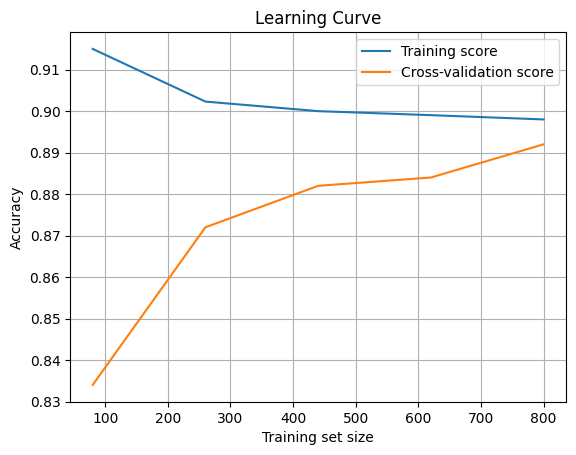

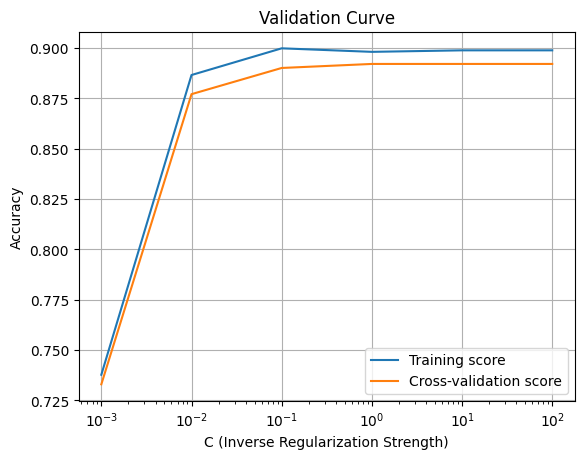

In [15]:
# Gambar learning curve
train_sizes, train_scores, test_scores = learning_curve(
    LogisticRegression(), X, y, cv=5, scoring='accuracy', train_sizes=np.linspace(0.1, 1.0, 5), random_state=2024)

train_mean = np.mean(train_scores, axis=1)
test_mean = np.mean(test_scores, axis=1)

plt.plot(train_sizes, train_mean, label='Training score')
plt.plot(train_sizes, test_mean, label='Cross-validation score')
plt.xlabel('Training set size')
plt.ylabel('Accuracy')
plt.title('Learning Curve')
plt.legend()
plt.grid(True)
plt.show()

# Gambar validation curve
param_range = np.logspace(-3, 2, 6)
train_scores, test_scores = validation_curve(
    LogisticRegression(), X, y, param_name="C", param_range=param_range,
    cv=5, scoring='accuracy')

train_mean = np.mean(train_scores, axis=1)
test_mean = np.mean(test_scores, axis=1)

plt.semilogx(param_range, train_mean, label='Training score')
plt.semilogx(param_range, test_mean, label='Cross-validation score')
plt.xlabel('C (Inverse Regularization Strength)')
plt.ylabel('Accuracy')
plt.title('Validation Curve')
plt.legend()
plt.grid(True)
plt.show()

In [16]:
# Nilai tepat kedua kurva (tambahan)
ts, tr, te = learning_curve(LogisticRegression(), X, y, cv=5, scoring='accuracy', train_sizes=np.linspace(0.1, 1.0, 5))
_, tr2, te2 = learning_curve(LogisticRegression(), X, y, cv=5, scoring='accuracy', train_sizes=np.linspace(0.1, 1.0, 5), random_state=7)
print("hasil learning_curve identik untuk random_state berbeda (shuffle=False)?", np.array_equal(tr, tr2) and np.array_equal(te, te2))
display(pd.DataFrame({"ukuran latih": ts, "latih": tr.mean(axis=1), "CV": te.mean(axis=1), "sd CV": te.std(axis=1),
                      "celah": tr.mean(axis=1) - te.mean(axis=1)}).round(4))
display(pd.DataFrame({"C": param_range, "latih": train_mean, "CV": test_mean, "sd CV": test_scores.std(axis=1)}).round(4))
print(f"proporsi kelas 1 = {y.mean():.3f} (baseline kelas mayoritas = {1 - y.mean():.3f})")

hasil learning_curve identik untuk random_state berbeda (shuffle=False)? True


,ukuran latih,latih,CV,sd CV,celah
0,80,0.9150,0.834,0.0340,0.0810
1,260,0.9023,0.872,0.0413,0.0303
2,440,0.9000,0.882,0.0254,0.0180
3,620,0.8990,0.884,0.0235,0.0150
4,800,0.8980,0.892,0.0242,0.0060


,C,latih,CV,sd CV
0,0.001,0.7377,0.733,0.0150
1,0.010,0.8865,0.877,0.0232
2,0.100,0.8998,0.890,0.0212
3,1.000,0.8980,0.892,0.0242
4,10.000,0.8988,0.892,0.0242
5,100.000,0.8988,0.892,0.0242


proporsi kelas 1 = 0.305 (baseline kelas mayoritas = 0.695)


**Interpretasi output.**

* ***Learning curve*:** dengan 80 sampel latih, akurasi latih 0,915 dan CV 0,834 (celah 0,081). Seiring bertambahnya data, akurasi latih **turun** sedikit (lebih sulit menghafal data yang lebih banyak) dan akurasi CV **naik**, sampai keduanya hampir bertemu pada 800 sampel (0,898 vs 0,892, celah 0,006). Kedua kurva sudah mendatar dan berdekatan, tanda **bias**, bukan variansi, yang membatasi model: menambah data tidak akan banyak menaikkan akurasi; yang dibutuhkan adalah model atau fitur yang lebih ekspresif.
* ***Validation curve*:** C = 0,001 jelas *underfit* (latih 0,738, CV 0,733, hampir sama dengan *baseline* 0,695). Mulai C = 0,1, kedua kurva mendatar di sekitar 0,90 (latih) dan 0,89 (CV). Tidak ada tanda *overfitting* bahkan pada C = 100, karena regresi logistik dengan 20 fitur dan 800 sampel latih tidak punya kapasitas untuk menghafal. Selisih CV antar-C ≥ 0,1 (≤ 0,002) jauh di bawah sd antar-fold (±0,02).
* Catatan kode: `learning_curve(..., random_state=2024)` tidak berpengaruh karena `shuffle=False` (default). Sel tambahan menjalankan ulang dengan `random_state` berbeda dan hasilnya identik.

### Poin Penting
* *Learning curve*: celah latih–CV menyempit dari 0,081 ke 0,006; kurva mendatar di ±0,89 → bias tinggi, data tambahan tidak banyak membantu.
* *Validation curve*: C = 0,001 *underfit*; C ≥ 0,1 mendatar tanpa *overfitting*.
* `random_state` di `learning_curve` hanya berlaku jika `shuffle=True`.

## Resep 12.6 — Latihan Praktis *Cross-Validation* dan Evaluasi

**Tujuan.** Menerapkan materi bab pada data sintetis seimbang: (1) CV 5-fold regresi logistik dengan empat metrik, (2) *grid search* `C` × kernel untuk SVC lalu evaluasi pada data uji, (3) *learning curve* dan *validation curve*.

### Teori

* **Latihan 1:** `cross_validate` dengan `scoring=["accuracy", "precision", "recall", "f1"]` sekaligus; pada data seimbang keempat metrik biasanya berdekatan.
* **Latihan 2:** *grid* 3 nilai `C` × 2 kernel (linear, RBF) = 6 kandidat × 5 fold = 30 fit, dijalankan **hanya pada data latih** (70 %), lalu model terbaik dinilai pada 30 % data uji dengan `classification_report`. Ini pola yang benar dari Resep 12.4.
* **Latihan 3:** kurva belajar dan validasi seperti Resep 12.5, kali ini pada data seimbang (`make_classification` default: 2 kelas seimbang, 10 fitur, 2 di antaranya informatif).

### Kode

### Kode — Latihan 1: *Cross-Validation* Model Regresi Logistik

In [17]:
# Muat pustaka
from sklearn.datasets import make_classification
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_validate

# Muat dataset
X, y = make_classification(n_samples=500, n_features=10, random_state=2024)

# Cross-validate dan kumpulkan metrik
model = LogisticRegression()
results = cross_validate(model, X, y, cv=5, scoring=["accuracy", "precision", "recall", "f1"])

for metric in ["test_accuracy", "test_precision", "test_recall", "test_f1"]:
    print(f"{metric}: {results[metric].mean():.3f}")

test_accuracy: 0.896
test_precision: 0.896
test_recall: 0.895
test_f1: 0.895


In [18]:
# Sebaran per fold (tambahan)
print(f"proporsi kelas 1 = {y.mean():.3f}")
print(pd.DataFrame({m: results[m] for m in ["test_accuracy", "test_precision", "test_recall", "test_f1"]}).round(3).T)

proporsi kelas 1 = 0.494
                    0     1      2      3      4
test_accuracy   0.820  0.94  0.890  0.910  0.920
test_precision  0.833  0.94  0.852  0.917  0.936
test_recall     0.800  0.94  0.939  0.898  0.898
test_f1         0.816  0.94  0.893  0.907  0.917


**Interpretasi output.** Pada data seimbang (49,4 % kelas 1), keempat metrik hampir identik: akurasi **0,896**, *precision* **0,896**, *recall* **0,895**, F1 **0,895**. Ketika kelas seimbang dan model tidak condong ke satu kelas, *precision* ≈ *recall* ≈ akurasi. Bandingkan dengan Resep 12.3 (data 70/30), tempat *recall* kelas minoritas tertinggal jauh dari akurasi. Skor per fold berkisar 0,82–0,94, sehingga rata-rata 5 fold jauh lebih dapat dipercaya daripada satu pembagian.

### Kode — Latihan 2: *Tuning* Hiperparameter dengan *Grid Search*

In [19]:
# Muat pustaka
from sklearn.model_selection import GridSearchCV, train_test_split
from sklearn.svm import SVC
from sklearn.metrics import classification_report

# Muat dan bagi dataset
X, y = make_classification(n_samples=500, n_features=10, random_state=2024)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=2024)

# Lakukan grid search
param_grid = {"C": [0.1, 1, 10], "kernel": ["linear", "rbf"]}
grid = GridSearchCV(SVC(), param_grid, cv=5)
grid.fit(X_train, y_train)
print(f"Best parameters: {grid.best_params_}")

# Evaluasi pada data uji
y_pred = grid.predict(X_test)
print(classification_report(y_test, y_pred))

Best parameters: {'C': 0.1, 'kernel': 'rbf'}
              precision    recall  f1-score   support

           0       0.94      0.86      0.89        84
           1       0.84      0.92      0.88        66

    accuracy                           0.89       150
   macro avg       0.89      0.89      0.89       150
weighted avg       0.89      0.89      0.89       150



In [20]:
# Papan peringkat grid (tambahan)
lb = pd.DataFrame(grid.cv_results_)[["param_C", "param_kernel", "mean_test_score", "std_test_score", "rank_test_score"]]
display(lb.sort_values("rank_test_score").round(4))
print(f"skor CV terbaik = {grid.best_score_:.4f}; akurasi uji = {grid.score(X_test, y_test):.4f}")

,param_C,param_kernel,mean_test_score,std_test_score,rank_test_score
1,0.1,rbf,0.8971,0.0190,1
3,1.0,rbf,0.8971,0.0246,1
4,10.0,linear,0.8971,0.0246,1
0,0.1,linear,0.8914,0.0232,4
2,1.0,linear,0.8914,0.0214,4
5,10.0,rbf,0.8543,0.0277,6


skor CV terbaik = 0.8971; akurasi uji = 0.8867


**Interpretasi output.** *Grid search* melaporkan `C=0.1, kernel='rbf'`, tetapi papan peringkat menunjukkan **tiga kandidat seri** di skor CV 0,8971 (RBF dengan C = 0,1 dan 1; linear dengan C = 10), dan dua kandidat linear lain hanya 0,006 di bawahnya. Satu-satunya pilihan yang jelas buruk adalah RBF dengan C = 10 (0,854), kemungkinan *overfit*. Pada data uji, model terpilih mencapai akurasi **0,887**, sedikit di bawah skor CV, dengan *recall* kelas 1 (0,92) lebih tinggi daripada kelas 0 (0,86). Seperti di Bab 8, "parameter terbaik" sering hanya pemenang pertama dari beberapa pengaturan yang setara.

### Kode — Latihan 3: Menilai Generalisasi dengan Kurva Belajar dan Validasi

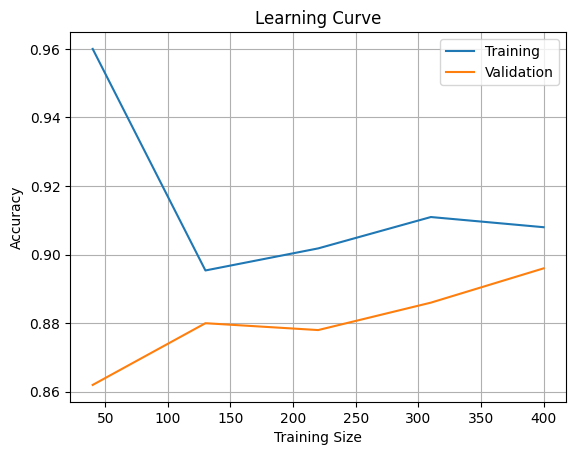

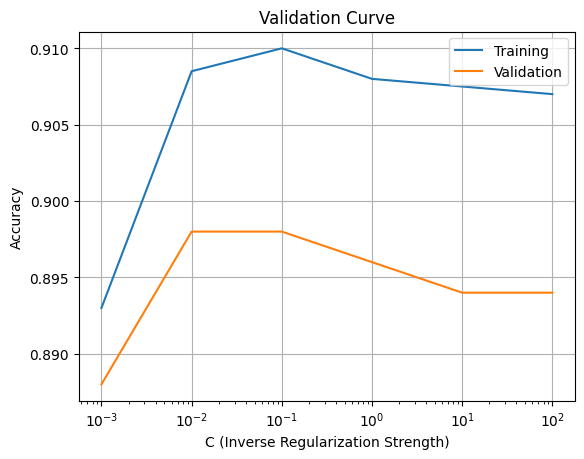

In [21]:
# Muat pustaka
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import learning_curve, validation_curve

# Gambar learning curve
train_sizes, train_scores, test_scores = learning_curve(
    LogisticRegression(), X, y, cv=5, scoring='accuracy', train_sizes=np.linspace(0.1, 1.0, 5), random_state=2024)

plt.plot(train_sizes, train_scores.mean(axis=1), label="Training")
plt.plot(train_sizes, test_scores.mean(axis=1), label="Validation")
plt.title("Learning Curve")
plt.xlabel("Training Size")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)
plt.show()

# Gambar validation curve
param_range = np.logspace(-3, 2, 6)
train_scores, test_scores = validation_curve(
    LogisticRegression(), X, y, param_name="C", param_range=param_range,
    cv=5, scoring='accuracy')

plt.semilogx(param_range, train_scores.mean(axis=1), label="Training")
plt.semilogx(param_range, test_scores.mean(axis=1), label="Validation")
plt.title("Validation Curve")
plt.xlabel("C (Inverse Regularization Strength)")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)
plt.show()

In [22]:
# Nilai tepat kedua kurva Latihan 3 (tambahan)
ts3, tr3, te3 = learning_curve(LogisticRegression(), X, y, cv=5, scoring='accuracy', train_sizes=np.linspace(0.1, 1.0, 5))
display(pd.DataFrame({"ukuran latih": ts3, "latih": tr3.mean(axis=1), "validasi": te3.mean(axis=1)}).round(4))
display(pd.DataFrame({"C": param_range, "latih": train_scores.mean(axis=1), "validasi": test_scores.mean(axis=1)}).round(4))

,ukuran latih,latih,validasi
0,40,0.9600,0.862
1,130,0.8954,0.880
2,220,0.9018,0.878
3,310,0.9110,0.886
4,400,0.9080,0.896


,C,latih,validasi
0,0.001,0.8930,0.888
1,0.010,0.9085,0.898
2,0.100,0.9100,0.898
3,1.000,0.9080,0.896
4,10.000,0.9075,0.894
5,100.000,0.9070,0.894


**Interpretasi output.** Pada data seimbang ini, *validation curve* sangat datar: akurasi validasi 0,888 pada C = 0,001 dan 0,894–0,898 untuk semua C lain. Berbeda dengan Resep 12.5, bahkan regularisasi terkuat tidak membuat model *underfit*, karena hanya 2 dari 10 fitur yang informatif dan sinyalnya mudah ditangkap. *Learning curve* (grafik pertama) memperlihatkan pola yang sama dengan Resep 12.5: celah latih–validasi menyempit dari 0,098 (40 sampel latih: 0,960 vs 0,862) menjadi 0,012 (400 sampel: 0,908 vs 0,896). Data dan model ini sudah berada di batas kemampuannya; perbaikan harus datang dari fitur atau model lain, bukan dari tuning C.

### Poin Penting
* Pada data seimbang, akurasi, *precision*, *recall*, dan F1 hampir sama (≈ 0,896).
* *Grid search* SVC: tiga kandidat seri di CV 0,897; akurasi uji model terpilih 0,887.
* *Validation curve* datar (0,888–0,898): tuning C hampir tidak berpengaruh pada data ini.

## Ringkasan Bab

| Resep | Konsep | Kelas/fungsi sklearn utama | Poin penting |
|---|---|---|---|
| 12.1 k-fold vs *stratified* | Rata-rata dan sebaran skor fold, proporsi kelas per fold | `KFold`, `StratifiedKFold` | 0,756 vs 0,766 (selisih < sd 0,063); stratifikasi menekan sebaran proporsi kelas dari 0,045 ke 0,010 pada data 10 % positif. |
| 12.2 LOOCV dan *nested* CV | $k=n$; tuning di loop dalam, penilaian di loop luar | `LeaveOneOut`, `GridSearchCV` dalam `cross_val_score` | LOOCV MSE 3.327,7 (442 fit); *nested* 0,480 adalah $R^2$, bukan MSE. |
| 12.3 API CV | Satu metrik, banyak metrik, tuning + refit | `cross_val_score`, `cross_validate`, `GridSearchCV` | 0,910 akurasi; *recall* kelas minoritas 0,820; C = 0,1 (0,918) hanya sedikit di atas default. |
| 12.4 Pemilihan Model | *Grid* vs *randomized search*, data uji terpisah | `GridSearchCV`, `RandomizedSearchCV`, `loguniform` | C = 0,1 vs 0,1744; uji 0,933 vs 0,940 (1 sampel). |
| 12.5 Generalisasi | *Learning curve*, *validation curve*, bias–variansi | `learning_curve`, `validation_curve` | Celah menyempit ke 0,006 → bias tinggi; C = 0,001 *underfit*, tanpa *overfit* di C besar. |
| 12.6 Latihan Praktis | Multi-metrik, *grid search* SVC, kurva | `cross_validate`, `GridSearchCV(SVC)` | 0,896 di semua metrik; tiga kandidat SVC seri; kurva validasi datar. |

**Langkah selanjutnya.** Bab ini memberi alat untuk mengukur kinerja secara jujur dan memilih model tanpa mengintip data uji. Hasilnya berulang di hampir setiap resep: banyak pilihan hiperparameter sama baiknya dalam batas variasi antar-fold, dan selisih kecil antar-model jarang bermakna. Bab 13 menutup *pipeline* ML: setelah model terpilih dan dievaluasi, bagaimana model itu disimpan, dijalankan di produksi, dipantau, dan diperbarui.

## Referensi

* Sukup, J. (2025). *scikit-learn Cookbook, Third Edition*. Packt Publishing. Bab 12.
* Repositori kode resmi: <https://github.com/PacktPublishing/Scikit-Learn-Cookbook-Third-Edition>
* scikit-learn User Guide — Cross-validation: evaluating estimator performance: <https://scikit-learn.org/1.5/modules/cross_validation.html>
* scikit-learn User Guide — Tuning the hyper-parameters of an estimator: <https://scikit-learn.org/1.5/modules/grid_search.html>
* scikit-learn User Guide — Validation curves: plotting scores to evaluate models: <https://scikit-learn.org/1.5/modules/learning_curve.html>
* Bergstra, J., & Bengio, Y. (2012). Random search for hyper-parameter optimization. *Journal of Machine Learning Research*, 13, 281–305.
* Cawley, G. C., & Talbot, N. L. C. (2010). On over-fitting in model selection and subsequent selection bias in performance evaluation. *Journal of Machine Learning Research*, 11, 2079–2107.
* Hastie, T., Tibshirani, R., & Friedman, J. (2009). *The Elements of Statistical Learning* (2nd ed.). Springer. Bab 7.